# Praktikum Data Mining — Evaluasi Model Klasifikasi
**Studi kasus:** klasifikasi gempa signifikan (M ≥ 5.0) di Sumatera Barat

**Dataset:** `BMKG_Earthquake_Catalog.csv`, `polygon_sumbar_valid.geojson`, `wilayah_sumbar.json`

Kelas positif (1) = gempa signifikan, setara dengan fraud pada modul.

In [1]:
import os

# Default: file data berada di folder yang SAMA dengan notebook ini.
# Contoh lain (Windows): DATA_DIR = r"C:\Users\NamaAnda\Documents\praktikum"
# Google Colab        : DATA_DIR = "/content"
DATA_DIR = "."

CSV_PATH     = f"{DATA_DIR}/BMKG_Earthquake_Catalog.csv"
GEOJSON_PATH = f"{DATA_DIR}/polygon_sumbar_valid.geojson"
WILAYAH_PATH = f"{DATA_DIR}/wilayah_sumbar.json"

# Kotak (bounding box) Sumatera Barat termasuk perairan Mentawai / lepas pantai
LAT_MIN, LAT_MAX = -3.5, 1.0
LON_MIN, LON_MAX = 98.3, 102.5

# Ambang magnitudo untuk label "signifikan"
MAG_THRESHOLD = 5.0

# Cek file sebelum dibaca, supaya pesan error lebih jelas
import os
for p in (CSV_PATH, GEOJSON_PATH, WILAYAH_PATH):
    if not os.path.exists(p):
        raise FileNotFoundError(
            f"File tidak ditemukan: {os.path.abspath(p)}\n"
            "Letakkan ketiga file data di folder yang sama dengan notebook, "
            "atau ubah DATA_DIR di atas."
        )
print("Folder kerja saat ini:", os.getcwd())
print("Semua file data ditemukan.")


Folder kerja saat ini: C:\Users\Intel Core i5\OneDrive - unp.ac.id\semester 5\DataMining\Pertemuan 9\Tugas
Semua file data ditemukan.


## 4.1 Menyiapkan Dataset

Membaca katalog gempa BMKG, memfilter wilayah Sumatera Barat, spatial join dengan poligon desa dan tabel wilayah, lalu membentuk fitur dan label `isSignifikan` (M ≥ 5.0).

In [2]:
import json
import numpy as np
import pandas as pd
from matplotlib.path import Path

gempa = pd.read_csv(CSV_PATH)
gempa["waktu"] = pd.to_datetime(
    gempa["Date"] + " " + gempa["Time (UTC)"], format="%d-%b-%Y %H:%M:%S", errors="coerce"
)
print("Total katalog gempa seluruh Indonesia:", len(gempa))

gempa = gempa[
    gempa["Latitude"].between(LAT_MIN, LAT_MAX)
    & gempa["Longitude"].between(LON_MIN, LON_MAX)
].dropna(subset=["waktu"]).reset_index(drop=True)
print("Gempa di sekitar Sumatera Barat       :", len(gempa))

with open(GEOJSON_PATH, encoding="utf-8") as f:
    geo = json.load(f)

def ring_to_path(ring):
    return Path(np.asarray(ring, dtype=float)[:, :2])

poligon = []  # tiap elemen: (bbox, [(exterior, [holes])], properti)
for feat in geo["features"]:
    geom = feat["geometry"]
    if geom is None:                     # beberapa fitur tidak punya geometri
        continue
    polys = [geom["coordinates"]] if geom["type"] == "Polygon" else geom["coordinates"]
    parts, xs, ys = [], [], []
    for poly in polys:
        ext = ring_to_path(poly[0])
        holes = [ring_to_path(h) for h in poly[1:]]
        parts.append((ext, holes))
        xs += list(ext.vertices[:, 0]); ys += list(ext.vertices[:, 1])
    bbox = (min(xs), min(ys), max(xs), max(ys))
    poligon.append((bbox, parts, feat["properties"]))
print("Jumlah poligon desa valid              :", len(poligon))

with open(WILAYAH_PATH, encoding="utf-8") as f:
    wilayah = pd.DataFrame(json.load(f))
kamus_wilayah = wilayah.set_index("kode")[["kabupaten", "kecamatan"]].to_dict("index")

titik = gempa[["Longitude", "Latitude"]].to_numpy()
kab = np.full(len(gempa), "Lepas pantai / di luar daratan", dtype=object)
kec = np.full(len(gempa), "-", dtype=object)
di_daratan = np.zeros(len(gempa), dtype=int)

for (x0, y0, x1, y1), parts, prop in poligon:
    kandidat = np.where(
        (titik[:, 0] >= x0) & (titik[:, 0] <= x1) & (titik[:, 1] >= y0) & (titik[:, 1] <= y1)
        & (di_daratan == 0)
    )[0]
    if len(kandidat) == 0:
        continue
    pts = titik[kandidat]
    dalam = np.zeros(len(kandidat), dtype=bool)
    for ext, holes in parts:
        m = ext.contains_points(pts)
        for h in holes:
            m &= ~h.contains_points(pts)
        dalam |= m
    idx = kandidat[dalam]
    if len(idx):
        info = kamus_wilayah.get(prop.get("KDEPUM"))       # cari di wilayah_sumbar.json
        nama_kab = info["kabupaten"] if info else "Kabupaten " + str(prop.get("WADMKK"))
        nama_kec = info["kecamatan"] if info else str(prop.get("WADMKC"))
        kab[idx], kec[idx], di_daratan[idx] = nama_kab, nama_kec, 1

gempa["kabupaten"] = kab
gempa["kecamatan"] = kec
gempa["di_daratan"] = di_daratan

# Magnitudo TIDAK dipakai sebagai fitur karena dipakai untuk membuat label
# (kalau dipakai, model "mencontek" jawaban / data leakage).
df = pd.DataFrame({
    "latitude":   gempa["Latitude"],
    "longitude":  gempa["Longitude"],
    "depth_km":   gempa["Depth (km)"],
    "hour":       gempa["waktu"].dt.hour,
    "month":      gempa["waktu"].dt.month,
    "di_daratan": gempa["di_daratan"],
    "isSignifikan": (gempa["Magnitude"] >= MAG_THRESHOLD).astype(int),
})

print(df.head())
print("\nDistribusi kelas:")
print(df["isSignifikan"].value_counts())
print("Proporsi gempa signifikan: {:.2%}".format(df["isSignifikan"].mean()))

print("\nJumlah gempa per kabupaten/kota (hasil spatial join):")
print(gempa["kabupaten"].value_counts())

Total katalog gempa seluruh Indonesia: 217807
Gempa di sekitar Sumatera Barat       : 7576
Jumlah poligon desa valid              : 1289
   latitude  longitude  depth_km  hour  month  di_daratan  isSignifikan
0     -1.19     101.84        30    17      4           0             0
1     -1.87      99.71        28    10      4           0             0
2     -0.38      99.80       100    22      6           0             0
3      0.78      99.80        10    18      5           0             0
4     -1.93     101.43        35     4      6           0             0

Distribusi kelas:
isSignifikan
0    7372
1     204
Name: count, dtype: int64
Proporsi gempa signifikan: 2.69%

Jumlah gempa per kabupaten/kota (hasil spatial join):
kabupaten
Lepas pantai / di luar daratan    5621
Kabupaten Pasaman Barat            600
Kabupaten Pasaman                  441
Kabupaten Agam                     296
Kabupaten Pesisir Selatan          121
Kabupaten Tanah Datar              102
Kabupaten Kepulauan M

## 4.2 Membagi Data dan Melatih Model

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

X = df.drop(columns="isSignifikan")
y = df["isSignifikan"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y)

model = DecisionTreeClassifier(max_depth=4, class_weight="balanced", random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Data latih:", len(y_train))
print("Data uji  :", len(y_test))

Data latih: 5303
Data uji  : 2273


## 4.3 Menghitung Confusion Matrix

In [4]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
print("Confusion matrix:\n", cm)
print(f"TP={tp}, TN={tn}, FP={fp}, FN={fn}")

Confusion matrix:
 [[1808  404]
 [  28   33]]
TP=33, TN=1808, FP=404, FN=28


## 4.4 Perhitungan Manual dan Verifikasi

In [5]:
accuracy  = (tp + tn) / (tp + tn + fp + fn)
precision = tp / (tp + fp) if tp + fp else 0
recall    = tp / (tp + fn) if tp + fn else 0
f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0
print(f"Accuracy={accuracy:.3f}; Precision={precision:.3f}; Recall={recall:.3f}; F1={f1:.3f}")

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
print(accuracy_score(y_test, y_pred),
      precision_score(y_test, y_pred, zero_division=0),
      recall_score(y_test, y_pred, zero_division=0),
      f1_score(y_test, y_pred, zero_division=0))

Accuracy=0.810; Precision=0.076; Recall=0.541; F1=0.133
0.8099428068631764 0.07551487414187644 0.5409836065573771 0.13253012048192772


## 4.5 Visualisasi Confusion Matrix

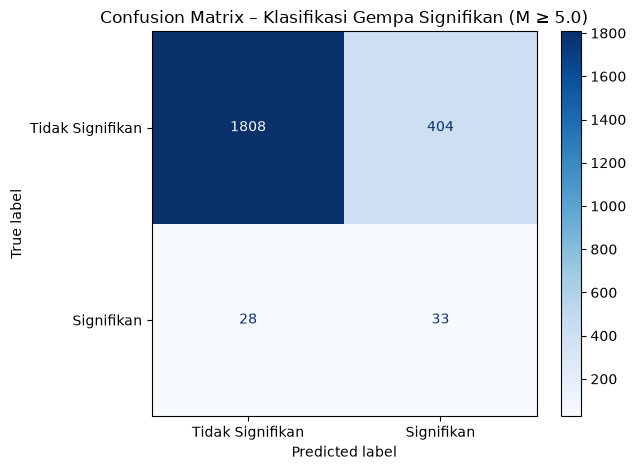

In [6]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay(confusion_matrix=cm,
                       display_labels=["Tidak Signifikan", "Signifikan"]
                       ).plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix – Klasifikasi Gempa Signifikan (M ≥ 5.0)")
plt.tight_layout()
plt.show()

## 4.6 Interpretasi dan Studi Kasus

In [7]:
print(f"""
Interpretasi (berdasarkan output di atas):
- TP = {tp}: gempa signifikan yang berhasil dikenali model.
- FN = {fn}: gempa signifikan yang LUPUT terdeteksi -> berbahaya, potensi
             peringatan dini tidak diberikan.
- FP = {fp}: gempa biasa yang salah ditandai signifikan -> alarm palsu,
             dapat menimbulkan kepanikan / biaya respons yang tidak perlu.
- TN = {tn}: gempa biasa yang benar dikenali.
Recall tinggi mengurangi gempa signifikan yang lolos, tetapi dapat menaikkan alarm palsu.
""")


Interpretasi (berdasarkan output di atas):
- TP = 33: gempa signifikan yang berhasil dikenali model.
- FN = 28: gempa signifikan yang LUPUT terdeteksi -> berbahaya, potensi
             peringatan dini tidak diberikan.
- FP = 404: gempa biasa yang salah ditandai signifikan -> alarm palsu,
             dapat menimbulkan kepanikan / biaya respons yang tidak perlu.
- TN = 1808: gempa biasa yang benar dikenali.
Recall tinggi mengurangi gempa signifikan yang lolos, tetapi dapat menaikkan alarm palsu.



## 4.7 Eksperimen: Baseline Semua "Tidak Signifikan"

In [8]:
from sklearn.metrics import classification_report

baseline = np.zeros(len(y_test), dtype=int)
print("Baseline accuracy:", accuracy_score(y_test, baseline))
print("Baseline:")
print(classification_report(y_test, baseline, labels=[0, 1], zero_division=0))
print("Decision Tree:")
print(classification_report(y_test, y_pred, labels=[0, 1], zero_division=0))

Baseline accuracy: 0.9731632204135504
Baseline:
              precision    recall  f1-score   support

           0       0.97      1.00      0.99      2212
           1       0.00      0.00      0.00        61

    accuracy                           0.97      2273
   macro avg       0.49      0.50      0.49      2273
weighted avg       0.95      0.97      0.96      2273

Decision Tree:
              precision    recall  f1-score   support

           0       0.98      0.82      0.89      2212
           1       0.08      0.54      0.13        61

    accuracy                           0.81      2273
   macro avg       0.53      0.68      0.51      2273
weighted avg       0.96      0.81      0.87      2273



## 4.8 Eksperimen: Pengaruh Ambang Prediksi (Threshold)

In [9]:
y_prob = model.predict_proba(X_test)[:, list(model.classes_).index(1)]
for threshold in [0.2, 0.4, 0.5, 0.7]:
    pred = (y_prob >= threshold).astype(int)
    print(threshold,
          "precision=", round(precision_score(y_test, pred, zero_division=0), 3),
          "recall=",    round(recall_score(y_test, pred, zero_division=0), 3))

0.2 precision= 0.039 recall= 0.934
0.4 precision= 0.056 recall= 0.623
0.5 precision= 0.076 recall= 0.541
0.7 precision= 0.093 recall= 0.459
